In [1]:
import pandas as pd

In [2]:
df = pd.read_csv(
    "https://drive.google.com/uc?id=1GWHKPdxVuqroKoKoB49zOEyfyLAwbzcc",
    encoding='latin1',
    index_col="Order ID", # set column as index
    parse_dates=["Order Date", "Ship Date"], # convert string to datetime
    date_format="%d-%m-%Y", # specify date format
    )

In [3]:
df.info()
df.head(2)

<class 'pandas.DataFrame'>
Index: 9994 entries, CA-2013-152156 to CA-2014-119914
Data columns (total 20 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Row ID         9994 non-null   int64         
 1   Order Date     9994 non-null   datetime64[us]
 2   Ship Date      9994 non-null   datetime64[us]
 3   Ship Mode      9994 non-null   str           
 4   Customer ID    9994 non-null   str           
 5   Customer Name  9994 non-null   str           
 6   Segment        9994 non-null   str           
 7   Country        9994 non-null   str           
 8   City           9994 non-null   str           
 9   State          9994 non-null   str           
 10  Postal Code    9994 non-null   int64         
 11  Region         9994 non-null   str           
 12  Product ID     9994 non-null   str           
 13  Category       9994 non-null   str           
 14  Sub-Category   9994 non-null   str           
 15  Product Name  

,Row ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
Order ID,,,,,,,,,,,,,,,,,,,,
CA-2013-152156,1,2013-11-09,2013-11-12,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96,2,0.0,41.9136
CA-2013-152156,2,2013-11-09,2013-11-12,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94,3,0.0,219.5820


# Racap
- boolean indexing: filter your rows by conditions, you can combine conditions with logical operators &, |, ~
- `isin()` lets you choose rows that are in a list of conditions, works like logical OR (|)
- `query()` simplifies the syntax and let's you write queries as you would in SQL

In [4]:
complex_filter = (df["Region"] == "South") & (df["Profit"] > 1500) & ~ (df["Segment"]== "Corporate")
df[complex_filter]


east_west = df["Region"].isin(["East", "West"])
df[east_west]

df.query("Category == 'Technology' and Sales > 300.0 and Discount == 0.0")

,Row ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
Order ID,,,,,,,,,,,,,,,,,,,,
CA-2013-105816,55,2013-12-12,2013-12-18,Standard Class,JM-15265,Janet Molinari,Corporate,United States,New York City,New York,10024,East,TEC-PH-10002447,Technology,Phones,AT&T CL83451 4-Handset Telephone,1029.95,5,0.0,298.6855
CA-2013-114489,148,2013-12-06,2013-12-10,Standard Class,JE-16165,Justin Ellison,Corporate,United States,Franklin,Wisconsin,53132,Central,TEC-PH-10000215,Technology,Phones,Plantronics Cordless Phone Headset with In-lin...,384.45,11,0.0,103.8015
CA-2013-114104,160,2013-11-21,2013-11-25,Standard Class,NP-18670,Nora Paige,Consumer,United States,Edmond,Oklahoma,73034,Central,TEC-PH-10004536,Technology,Phones,Avaya 5420 Digital phone,944.93,7,0.0,236.2325
CA-2011-158274,183,2011-11-19,2011-11-24,Second Class,RM-19675,Robert Marley,Home Office,United States,Monroe,Louisiana,71203,South,TEC-PH-10003273,Technology,Phones,AT&T TR1909W,503.96,4,0.0,131.0296
CA-2013-145625,252,2013-09-12,2013-09-18,Standard Class,KC-16540,Kelly Collister,Consumer,United States,San Diego,California,92037,West,TEC-AC-10003832,Technology,Accessories,Logitech P710e Mobile Speakerphone,3347.37,13,0.0,636.0003
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
CA-2013-125220,9514,2013-10-15,2013-10-20,Standard Class,BE-11410,Bobby Elias,Consumer,United States,Appleton,Wisconsin,54915,Central,TEC-AC-10003033,Technology,Accessories,Plantronics CS510 - Over-the-Head monaural Wir...,1649.75,5,0.0,544.4175
CA-2014-152975,9579,2014-09-15,2014-09-17,First Class,RB-19705,Roger Barcio,Home Office,United States,New York City,New York,10035,East,TEC-PH-10004586,Technology,Phones,Wilson SignalBoost 841262 DB PRO Amplifier Kit,1079.85,3,0.0,323.9550
US-2014-135986,9690,2014-06-21,2014-06-28,Standard Class,PG-18895,Paul Gonzalez,Consumer,United States,Richmond,Virginia,23223,South,TEC-PH-10003691,Technology,Phones,BlackBerry Q10,503.96,4,0.0,125.9900


# `groupby()`
- `groupby()` helps you answer questions about sub-groups in your data
- splits data into distinct subsets, based on a key (here `Category`)
- an aggregation is needed to condenses multiple records into summary figures (here `mean()`)
- the aggregation is computed independently on each group

In [14]:
df.groupby("Category")["Discount"].mean()

Category
Furniture          0.173923
Office Supplies    0.157285
Technology         0.132323
Name: Discount, dtype: float64

In [ ]:
# choosing two different columns to aggregate gives you a DataFrame with summary statistics per group
df.groupby("Category")[["Sales", "Profit", "Discount"]].mean()

,Sales,Profit,Discount
Category,,,
Furniture,349.834887,8.699327,0.173923
Office Supplies,119.324101,20.327050,0.157285
Technology,452.709276,78.752002,0.132323


The `.agg()` method allows you to apply multiple aggregation functions simultaneously or customize metrics per column using dictionaries.

In [146]:
# Multiple metrics on a single column
df.groupby("Category")["Sales"].agg(["count", "mean", "median", "std"])

,count,mean,median,std
Category,,,,
Furniture,2121,349.834887,182.220,503.179145
Office Supplies,6026,119.324101,27.418,382.182228
Technology,1847,452.709276,166.160,1108.655848


In [ ]:
# the above is similar to the `describe()` method applied to a single column grouped by the key 'Category'
df.groupby("Category")["Sales"].describe()

,count,mean,std,min,25%,50%,75%,max
Category,,,,,,,,
Furniture,2121.0,349.834887,503.179145,1.892,47.040,182.220,435.168,4416.174
Office Supplies,6026.0,119.324101,382.182228,0.444,11.760,27.418,79.920,9892.740
Technology,1847.0,452.709276,1108.655848,0.990,68.016,166.160,448.534,22638.480


In [149]:
df["Quantity"]

Order ID
CA-2013-152156    2
CA-2013-152156    3
CA-2013-138688    2
US-2012-108966    5
US-2012-108966    2
                 ..
CA-2011-110422    3
CA-2014-121258    2
CA-2014-121258    2
CA-2014-121258    4
CA-2014-119914    2
Name: Quantity, Length: 9994, dtype: int64

In [148]:
# it is possible to apply different aggregations across different columns
df.groupby(["Region", "Category"]).agg({
    "Sales": ["sum", "mean"],
    "Profit": ["sum", "min", "max", "std"],
    "Quantity": "sum"
})

Sales                  Profit             \
                                 sum        mean         sum        min   
Region  Category                                                          
Central Furniture        163797.1638  340.534644  -2871.0494  -566.5625   
        Office Supplies  167026.4150  117.458801   8879.9799 -3701.8928   
        Technology       170416.3120  405.753124  33697.4320 -1359.9920   
East    Furniture        208291.2040  346.574383   3046.1658 -1665.0522   
        Office Supplies  205516.0550  120.044425  41014.5791 -1049.3406   
        Technology       264973.9810  495.278469  47462.0351 -6599.9780   
South   Furniture        117298.6840  353.309289   6771.2061 -1862.3124   
        Office Supplies  125651.3130  126.282727  19986.3928 -1306.5504   
        Technology       148771.9080  507.753952  19991.8314 -3839.9904   
West    Furniture        252612.7435  357.302325  11504.9503  -814.4832   
        Office Supplies  220853.2490  116.422377  52609.8490  -694.2936   
        Technology       251991.8320  420.687533  44303.6496 -3399.9800   

                                               Quantity  
                               max         std      sum  
Region  Category                                         
Central Furniture         770.3520  139.952020     1827  
        Office Supplies  4946.3700  269.520216     5409  
        Technology       8399.9760  443.909891     1544  
East    Furniture        1013.1270  141.821824     2214  
        Office Supplies  1453.1238  105.995426     6462  
        Technology       5039.9856  524.084817     1942  
South   Furniture         746.4078  178.304669     1291  
        Office Supplies  3177.4750  156.440304     3800  
        Technology       2799.9840  360.621959     1118  
West    Furniture         629.0100   99.926279     2696  
        Office Supplies  1906.4850   93.640005     7235  
        Technology       6719.9808  347.320239     2335

# `xs()`
- the above output is a MultiIndex DataFrame, where the index and columns have two levels
- `xs()` let's you select data at a particular level of a MultiIndex

In [156]:
multiindex = df.groupby(["Region", "Category"]).agg({
    "Sales": ["sum", "mean"],
    "Profit": ["sum", "min", "max"],
    "Quantity": "sum"
})

multiindex

Sales                  Profit             \
                                 sum        mean         sum        min   
Region  Category                                                          
Central Furniture        163797.1638  340.534644  -2871.0494  -566.5625   
        Office Supplies  167026.4150  117.458801   8879.9799 -3701.8928   
        Technology       170416.3120  405.753124  33697.4320 -1359.9920   
East    Furniture        208291.2040  346.574383   3046.1658 -1665.0522   
        Office Supplies  205516.0550  120.044425  41014.5791 -1049.3406   
        Technology       264973.9810  495.278469  47462.0351 -6599.9780   
South   Furniture        117298.6840  353.309289   6771.2061 -1862.3124   
        Office Supplies  125651.3130  126.282727  19986.3928 -1306.5504   
        Technology       148771.9080  507.753952  19991.8314 -3839.9904   
West    Furniture        252612.7435  357.302325  11504.9503  -814.4832   
        Office Supplies  220853.2490  116.422377  52609.8490  -694.2936   
        Technology       251991.8320  420.687533  44303.6496 -3399.9800   

                                   Quantity  
                               max      sum  
Region  Category                             
Central Furniture         770.3520     1827  
        Office Supplies  4946.3700     5409  
        Technology       8399.9760     1544  
East    Furniture        1013.1270     2214  
        Office Supplies  1453.1238     6462  
        Technology       5039.9856     1942  
South   Furniture         746.4078     1291  
        Office Supplies  3177.4750     3800  
        Technology       2799.9840     1118  
West    Furniture         629.0100     2696  
        Office Supplies  1906.4850     7235  
        Technology       6719.9808     2335

In [ ]:

# multiindex.xs("South") # defaults to axis=0, level=0
# multiindex.xs("Profit", axis=1) # selects 'Sales' column from the columns -> axis=1, level=0
# multiindex.xs("sum", axis=1, level=1) # selects all 'sum' columns (axis=1) on the second level (level=1)
multiindex.xs(("Central", "Furniture"), level=(0, 1)) # specify first and second index levels to select a single row

Sales      Profit  Quantity
Region  Category                                          
Central Furniture        163797.1638  -2871.0494      1827
        Office Supplies  167026.4150   8879.9799      5409
        Technology       170416.3120  33697.4320      1544
East    Furniture        208291.2040   3046.1658      2214
        Office Supplies  205516.0550  41014.5791      6462
        Technology       264973.9810  47462.0351      1942
South   Furniture        117298.6840   6771.2061      1291
        Office Supplies  125651.3130  19986.3928      3800
        Technology       148771.9080  19991.8314      1118
West    Furniture        252612.7435  11504.9503      2696
        Office Supplies  220853.2490  52609.8490      7235
        Technology       251991.8320  44303.6496      2335

aggregations can be assigned to custom names to avoid complex multindex DataFrames

In [37]:
# Named aggregation for clean, flat column names
df.groupby("Region").agg(
    total_sales=("Sales", "sum"),
    avg_profit=("Profit", "mean"),
    customer_count=("Customer ID", "nunique")
)

,total_sales,avg_profit,customer_count
Region,,,
Central,501239.8908,17.092709,629
East,678781.2400,32.135808,674
South,391721.9050,28.857673,512
West,725457.8245,33.849032,686


# `transform()`
- returns a DataFrame with the same shape as the original, and attaches the aggregations in a seperate column

In [162]:
df["Regional_Sum_of_Sales"] = df.groupby("Region")["Sales"].transform("sum")

# the rows are seperate, only the total sales per region is grouped
df[['Customer ID', 'Region','Sales', 'Quantity','Regional_Sum_of_Sales']].head(20)

,Customer ID,Region,Sales,Quantity,Regional_Sum_of_Sales
Order ID,,,,,
CA-2013-152156,CG-12520,South,261.9600,2,391721.9050
CA-2013-152156,CG-12520,South,731.9400,3,391721.9050
CA-2013-138688,DV-13045,West,14.6200,2,725457.8245
US-2012-108966,SO-20335,South,957.5775,5,391721.9050
US-2012-108966,SO-20335,South,22.3680,2,391721.9050
CA-2011-115812,BH-11710,West,48.8600,7,725457.8245
CA-2011-115812,BH-11710,West,7.2800,4,725457.8245
CA-2011-115812,BH-11710,West,907.1520,6,725457.8245
CA-2011-115812,BH-11710,West,18.5040,3,725457.8245


In [228]:
# because 'Regional_Sum_of_Sales' is present in each row, you can do row-wise calculations
df["Pct_of_Region_Sales"] = (df["Sales"] / df.groupby("Region")["Sales"].transform("sum"))*100

In [ ]:

# show it
df[['Customer ID', 'Region','Sales', 'Quantity','Regional_Sum_of_Sales', 'Pct_of_Region_Sales']].head()

# Column Math, Feature Engineering & `.assign()`

In [ ]:
# Direct vectorized column arithmetic
gross_revenue = df["Sales"] * df["Quantity"]
profit_margin = df["Profit"] / df["Sales"]

Order ID
CA-2013-152156    0.1600
CA-2013-152156    0.3000
CA-2013-138688    0.4700
US-2012-108966   -0.4000
US-2012-108966    0.1125
                   ...  
CA-2011-110422    0.1625
CA-2014-121258    0.1700
CA-2014-121258    0.0750
CA-2014-121258    0.4500
CA-2014-119914    0.3000
Length: 9994, dtype: float64

## `assign()`
- .assign() is the "add columns" tool: It creates and attaches new columns to your table, returning a fresh DataFrame without changing or breaking the original df.
- lambda df_: is a temporary shortcut: A lambda is just a quick, one-line mini-function. In this example, df_ represents the DataFrame being worked on.

In [233]:
# Idiomatic feature engineering using .assign() with lambda functions
df_featured = (
    df.assign(
        Gross_Revenue=lambda df_: df_["Sales"] * df_["Quantity"],
        Discount_Amount=lambda df_: df_["Sales"] * df_["Discount"],
        Net_Sales=lambda df_: df_["Sales"] - df_["Discount_Amount"],
        Profit_Margin=lambda df_: (df_["Profit"] / df_["Sales"]).round(4),
        Is_Profitable=lambda df_: df_["Profit"] > 0.0
    )
)

df_featured[['Sales', 'Quantity', 'Discount', 'Profit', 'Pct_of_Region_Sales',
       'Regional_Sum_of_Sales', 'Gross_Revenue', 'Discount_Amount',
       'Net_Sales', 'Profit_Margin', 'Is_Profitable']].head(3)

,Sales,Quantity,Discount,Profit,Pct_of_Region_Sales,Regional_Sum_of_Sales,Gross_Revenue,Discount_Amount,Net_Sales,Profit_Margin,Is_Profitable
Order ID,,,,,,,,,,,
CA-2013-152156,261.96,2,0.0,41.9136,0.066874,391721.9050,523.92,0.0,261.96,0.16,True
CA-2013-152156,731.94,3,0.0,219.5820,0.186852,391721.9050,2195.82,0.0,731.94,0.30,True
CA-2013-138688,14.62,2,0.0,6.8714,0.002015,725457.8245,29.24,0.0,14.62,0.47,True


# `pivot_table()`

In [84]:
pd.pivot_table(df, values="Sales", index="Region") # defualts to mean

pd.pivot_table(df, values="Sales", index="Region", aggfunc=sum) # defualts to mean
df.groupby("Region")['Sales'].sum() # aquivalent to above pivot_table

# the parameter take more than one argument, and you can create complex tables with it
pd.pivot_table(df,
               values=["Sales"],
               columns=["Category", "Sub-Category"],
               index="Region",
               aggfunc=["sum"],
               margins=True,
               margins_name="Total Sales")

sum                                                      \
                    Sales                                                       
Category        Furniture                                     Office Supplies   
Sub-Category    Bookcases      Chairs Furnishings      Tables      Appliances   
Region                                                                          
Central        24157.1768   85230.646   15254.370   39154.971       23582.033   
East           43819.3340   96260.683   29071.380   39139.807       34188.466   
South          10899.3620   45176.446   17306.684   43916.192       19525.326   
West           36004.1235  101781.328   30072.730   84754.562       30236.336   
Total Sales   114879.9963  328449.103   91705.164  206965.532      107532.161   

                                                                     \
                                                                      
Category                                                              
Sub-Category        Art     Binders  Envelopes Fasteners     Labels   
Region                                                                
Central        5765.340   56923.282   4636.872   778.030   2451.472   
East           7485.764   53497.997   4375.874   819.718   2602.934   
South          4655.622   37030.341   3345.556   503.316   2353.180   
West           9212.066   55961.113   4118.100   923.216   5078.726   
Total Sales   27118.792  203412.733  16476.402  3024.280  12486.312   

                                                                        \
                                                                         
Category                                        Technology               
Sub-Category      Paper     Storage   Supplies Accessories     Copiers   
Region                                                                   
Central       17491.902   45930.112   9467.372   33956.076   37259.570   
East          20172.602   71612.584  10760.116   45033.372   53219.462   
South         14150.984   35768.060   8318.928   27276.754    9299.756   
West          26663.718   70532.852  18127.122   61114.116   49749.242   
Total Sales   78479.206  223843.608  46673.538  167380.318  149528.030   

                                                    
                                                    
Category                               Total Sales  
Sub-Category    Machines      Phones                
Region                                              
Central        26797.384   72403.282  5.012399e+05  
East           66106.165  100614.982  6.787812e+05  
South          53890.960   58304.438  3.917219e+05  
West           42444.122   98684.352  7.254578e+05  
Total Sales   189238.631  330007.054  2.297201e+06

# `crosstab()`
- creates contingency tables for categorical columns 
- use to analyse frequency distributions 
- has `normalize=`parameter to check proportions

In [92]:
df_clean = df.reset_index(drop=True)
pd.crosstab(df_clean["Region"], df_clean["Segment"], normalize="columns", margins=True, margins_name="% of Total")

Segment,Consumer,Corporate,Home Office,% of Total
Region,,,,
Central,0.233481,0.222848,0.245653,0.232439
East,0.282990,0.290397,0.281548,0.284971
South,0.161433,0.168874,0.152552,0.162097
West,0.322096,0.317881,0.320247,0.320492


# `rank()`

In [169]:
# rank() creates a ranking with different tie-handling methods (like average, min, max, first, and dense)
df.groupby("Segment")["Profit"].sum().rank(ascending=False)

Segment
Consumer       1.0
Corporate      2.0
Home Office    3.0
Name: Profit, dtype: float64

# Visualizations

<Axes: >

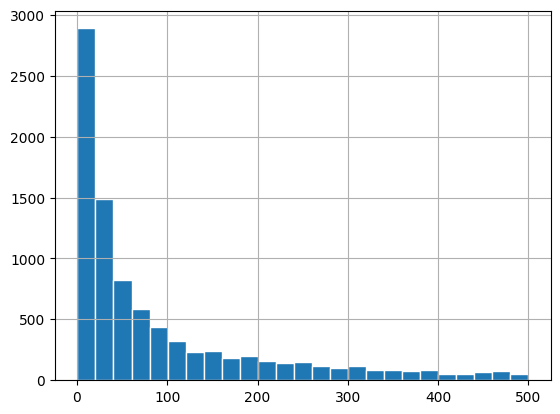

In [178]:
# df["Discount"].hist()
df.query("Sales < 500")["Sales"].hist(bins=25, edgecolor="white")

<Axes: title={'center': 'Profit'}, xlabel='Category'>

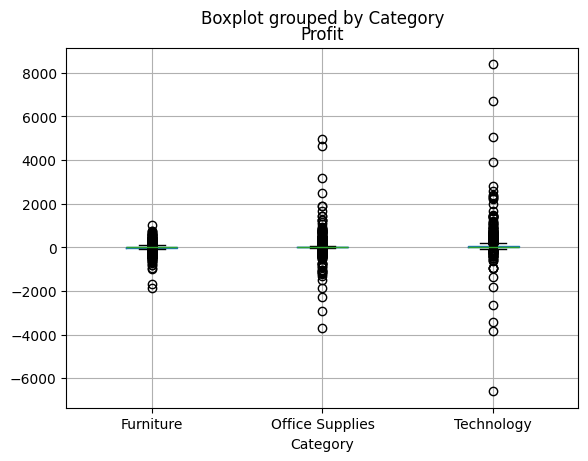

In [185]:
# Boxplot → outliers
# df.boxplot(column="Discount")
# df.plot(kind="box", y="Profit", title="Profit Spread and Outliers")
# df.boxplot(column="Profit", by="Category")

<Axes: >

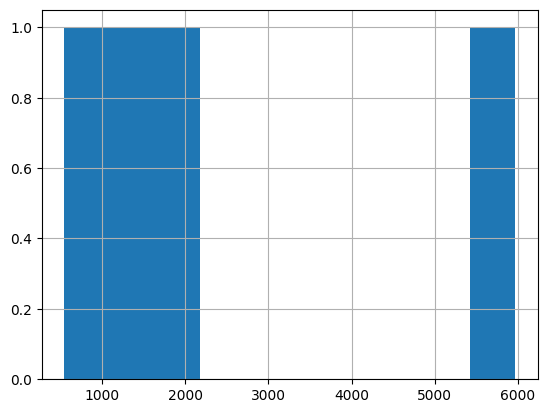

In [187]:
# df["Ship Mode"].value_counts().plot(kind="bar", title="Order Volume by Shipping Mode", rot=45)
# df["Ship Mode"].value_counts()
df.groupby("Region")["Sales"].sum().plot(kind="bar", title="Total Sales by Region", rot=0)

<Axes: title={'center': 'Top 10 Sub-Categories'}, ylabel='Sub-Category'>

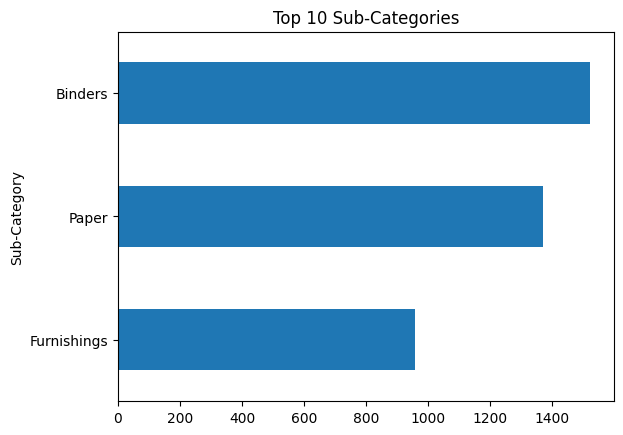

In [ ]:
# horizontal bar chart on count of sub-categories, reduced to top 3 (head(3)), sorted to show most freuquent first
df["Sub-Category"].value_counts().head(3).sort_values().plot(kind="barh", title="Top 10 Sub-Categories")

<Axes: title={'center': 'Total Profit by Category'}, ylabel='Category'>

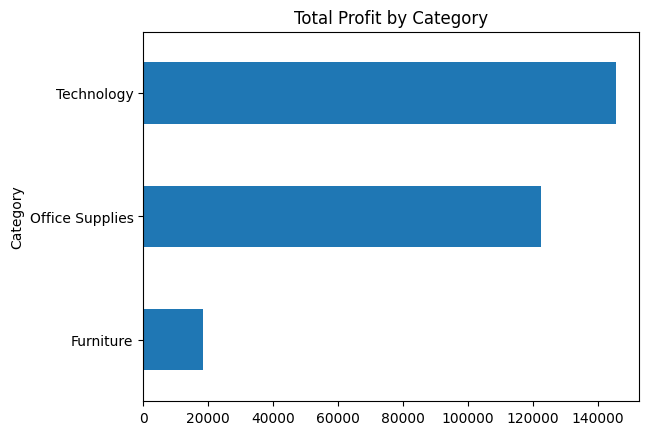

In [ ]:
# horizontal bar chart, on sum of profits by region
df.groupby("Category")["Profit"].sum().plot(kind="barh", title="Total Profit by Category")

<Axes: title={'center': 'Daily Sales Trend'}, xlabel='Order Date'>

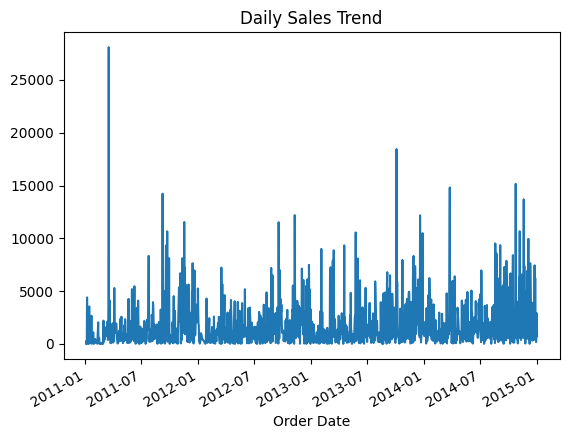

In [227]:
df.groupby("Order Date")["Sales"].sum().plot(kind="line", title="Daily Sales Trend")

In [ ]:

# .resample() groups time-based data into fixed intervals (like daily or monthly)
df.set_index("Order Date")["Sales"].resample("ME").sum().plot(kind="line", title="Monthly Sales")

In [ ]:
# Save plot → reuse
plt.savefig("plot.png")

# Pandas Pipeline

Axes(0.125,0.11;0.775x0.77)


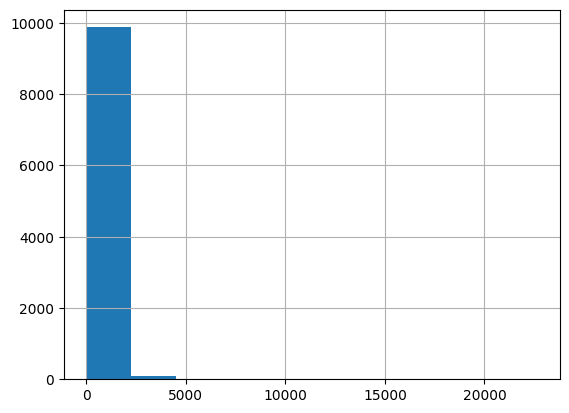

In [ ]:
url = "https://drive.google.com/uc?id=1GWHKPdxVuqroKoKoB49zOEyfyLAwbzcc"


def marco_pipe(url):

    df = pd.read_csv(
    url,
    encoding='latin1',
    index_col="Order ID", # set column as index
    parse_dates=["Order Date", "Ship Date"], # convert string to datetime
    date_format="%d-%m-%Y", # specify date format
    )

    # simple return
    return print(df["Sales"].hist(bins=10))


marco_pipe(url)

              Sales       Profit
count   9994.000000  9994.000000
mean     229.858001    28.656896
std      623.245101   234.260108
min        0.444000 -6599.978000
25%       17.280000     1.728750
50%       54.490000     8.666500
75%      209.940000    29.364000
max    22638.480000  8399.976000


{'summary': None, 'plot': <Axes: >}

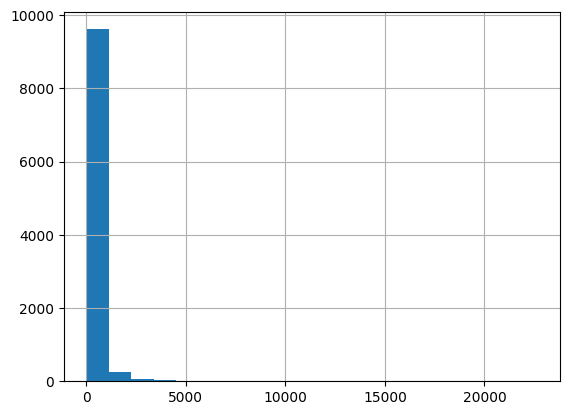

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

def marco_pipe(url):
    df = pd.read_csv(
        url,
        encoding="latin1",
        index_col="Order ID",
        parse_dates=["Order Date", "Ship Date"],
        date_format="%d-%m-%Y"
    )

    # Summary statistics
    summary_stats = df[["Sales", "Profit"]].describe()

    # visualitaion
    sales_hist = df["Sales"].hist(bins=20)

    # Return a structured dictionary, for more than one element
    return {
        "summary": print(summary_stats),
        "plot": sales_hist
    }


marco_pipe(url)

In [97]:
import seaborn as sns
import matplotlib.pyplot as plt

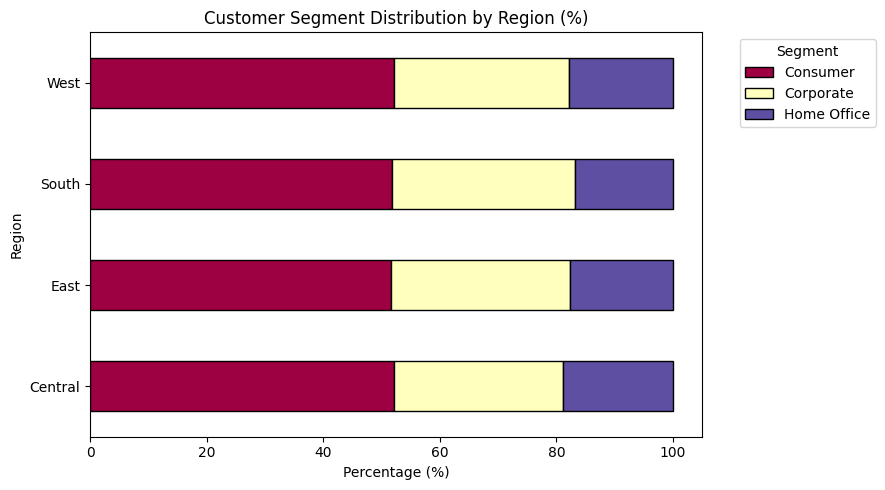

In [101]:
# Normalized row-wise distribution
segment_mix = pd.crosstab(df_clean["Region"], df_clean["Segment"], normalize="index") * 100

# Plot 100% stacked horizontal bars
segment_mix.plot(
    kind="barh",
    stacked=True,
    figsize=(9, 5),
    colormap="Spectral",
    edgecolor="black"
)

plt.title("Customer Segment Distribution by Region (%)")
plt.xlabel("Percentage (%)")
plt.ylabel("Region")
plt.legend(title="Segment", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()